# Retrieval validation

The step-by-step validation of `hyperphase.retrieval` on one simulated dataset: the likelihood and its landscape, nested sampling with every insolation model (`hyperillum`, the truth's; `naive`; `naive_redist`, with the heat redistribution $F$ as a third parameter), the evidence against a brute-force integral, and the posterior post-processing. `run_dynesty.py` is the batch version of sections 1–3; `01_retrieval_example.ipynb` reads its results back.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from dataclasses import replace
from hyperphase.defaults import (A_B_BOUNDS, DEFAULT_A, DEFAULT_A_B, DEFAULT_N_BINS, DEFAULT_N_ORBITS, DEFAULT_U, DEFAULT_U_BOL, F_BOUNDS,
                                 OFFSET_BOUNDS)
from hyperphase.model import ConstantBandAlbedo, FittingConfig, model_pcurve, pcurve_params
from hyperphase.phasecurve import occultation_depth
from hyperphase.plotting.retrieval import plot_bias, plot_derived, plot_evidence_jitter, plot_noisy_vs_truth, plot_posterior_overlay
from hyperphase.retrieval.likelihood import derived_samples, evidence_bruteforce, GaussianLogL, grid_max, logl_grid, logl_slice, theta_of
from hyperphase.retrieval.priors import Parameter, ParameterSet, Uniform
from hyperphase.retrieval.sampler import bayes_factor, brightness_temperature, equal_samples, posterior_summary, run_nested_fit, SamplerConfig
from hyperphase.retrieval.simulate import simulate_data
from hyperphase.retrieval.storage import dataset_tag
from hyperphase.bands import filter_lambda, filter_loc
from hyperphase.noise import rms_1min
from hyperphase.targets import hi_planets_by_name
import fspiderman as sp
from dynesty import utils as dyfunc
import time

In [2]:
# Target planet: from the NASA Exoplanet Archive, or a curated entry of inputs/planets/curated_planets.csv (K2-141 b: Malavolta et al. 2018, Barragán et al. 2018)
planet = hi_planets_by_name("TOI-2431 b") # "K2-141 b", "TOI-2431 b"

u, u_bol = DEFAULT_U, DEFAULT_U_BOL   # transit and irradiance limb darkening (baseline settings, hyperphase/defaults.py)

A_B_true = DEFAULT_A_B   # injected Bond albedo (baseline settings, hyperphase/defaults.py)

INSOL_TRUTH = "hyperillum"  # insolation model used to generate the simulated truth

A_model = ConstantBandAlbedo(DEFAULT_A)   # band-integrated albedo A of the reflected light, independent of A_B

# Filter to be used
instrument = "MIRI/LRS"
lrs_path = filter_loc(instrument)
lrs_range = filter_lambda(instrument)

n_bins = DEFAULT_N_BINS # number of bins in one orbit
n_orbits = DEFAULT_N_ORBITS # number of orbits observed
sigma_1min = rms_1min(planet, instrument, lrs_range)   # noise of a one-minute integration [ppm] in the chosen band (PandExo, served from the cache)
print(f"\nNoise Level (1min) = {sigma_1min:.1f} ppm")

seed = 44   # the noise realisation of the MIRI/LRS example retrieval (example_runs/): its ln B lies close to the expected value

l1, l2 = lrs_range

# context for simulating data functions
cfg = FittingConfig(planet=planet, filter_path=lrs_path, l1=l1, l2=l2, A_=A_model,
                    sigma_1min=sigma_1min, n_orbits=n_orbits, n_bins=n_bins, reflected=True, u_bol=u_bol, u=u)

print(f"period = {planet.period*24*60:.1f} min -> {n_bins} bins of {planet.period*24*60/n_bins:.1f} min")
print(f"1-sigma per bin (over all orbits) = {cfg.sigma_bin:.1f} ppm")

TOI-2431 b [MIRI/LRS]: sigma_1min = 62.93 ppm from the PandExo cache

Noise Level (1min) = 62.9 ppm
period = 322.8 min -> 27 bins of 12.0 min
1-sigma per bin (over all orbits) = 8.1 ppm


## 1. Simulated data

One noise realisation (seed `seed`) of the hyperillumination truth, binned as observed.

sigma_bin: 8.14 ppm  (bin width 11.96 min)
chi2 / n_bins (normalized average noise per bin ~1): 0.58
residual mean / sigma (~0): 0.12


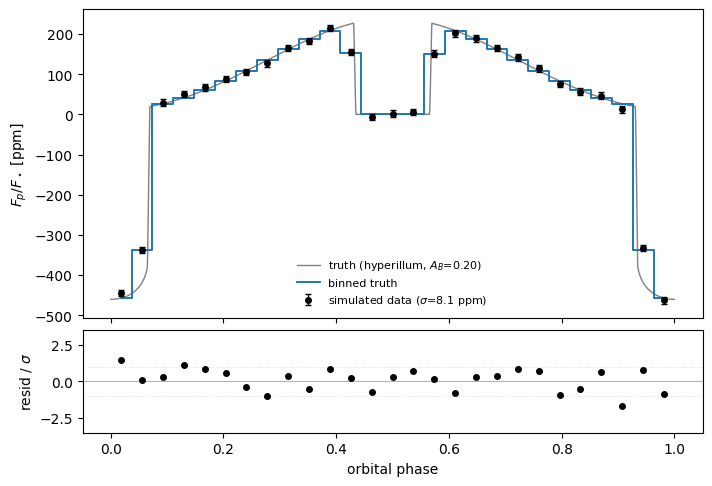

In [3]:
# SIMULATED OBSERVATION
data = simulate_data(cfg, A_B_true, insolation_model=INSOL_TRUTH, seed=seed)

## 2. Likelihood

`GaussianLogL` is the callable dynesty samples, `theta -> lnL` with `theta` ordered by `names`; everything not sampled goes into `fixed`:

$$\ln\mathcal{L}(\theta) = -\tfrac{1}{2}\sum_i\left[\left(\frac{y_i-m_i(\theta)}{s_i}\right)^2 + \ln\left(2\pi s_i^2\right)\right].$$

Each model has its own `ParameterSet`: $(A_B, \mathrm{offset})$, plus $F$ for `naive_redist`, which at $F = 0$ is the naive model (both $\ln\mathcal{L}$ at the truth are printed).

In [4]:
N_JOBS = -1 # use every core

# ParameterSet holds everything about the free parameters: it fixes the column order of theta and of res.samples, supplies the dynesty ptform, carries the LaTeX labels, and hands evidence_bruteforce the same prior box the sampler used.
# Uniform priors over the shared ranges of hyperphase.defaults: the physical A_B_BOUNDS and F_BOUNDS, and OFFSET_BOUNDS. Each model is sampled with its OWN set (PSETS): only "naive_redist" has F.
_A_B    = Parameter("A_B",    Uniform(*A_B_BOUNDS), r"$A_B$")
_OFFSET = Parameter("offset", Uniform(*OFFSET_BOUNDS), "offset [ppm]")
_F      = Parameter("F",      Uniform(*F_BOUNDS), r"$F$")
pset  = ParameterSet((_A_B, _OFFSET))                                            # the (A_B, offset) box every model has - what the shared grids below are built on
PSETS = {"hyperillum": pset, "naive": pset, "naive_redist": ParameterSet((_A_B, _OFFSET, _F))}
MODELS = ("hyperillum", "naive", "naive_redist")

A_grid, O_grid = pset.grid("A_B", 61),  pset.grid("offset", 201)
A_fine, O_fine = pset.grid("A_B", 201), pset.grid("offset", 401)
base  = dict(A_B=A_B_true, offset=0., F=0.) # the injected truth: no redistribution in the data, so F = 0 is the truth for naive_redist too
COLOR = {"naive": "C0", "hyperillum": "C3", "naive_redist": "C2"}
F_MODELS = [m for m in MODELS if "F" in PSETS[m].names]

# LogLikelihoods. Same data for every model, each with its own pset
logls = {m: GaussianLogL.from_pset(cfg, data, m, PSETS[m]) for m in MODELS}

for m, L in logls.items():
    th = theta_of(L, base)
    L(th)  # warm up
    t0 = time.perf_counter(); val = L(th); dt = time.perf_counter() - t0
    print(f"{L!r}   bounds {PSETS[m].bounds}")
    print(f"   lnL(truth) = {val:9.2f}   chi2 = {L.chi2(th):6.1f} / {cfg.n_bins} bins   {dt*1e3:6.0f} ms/call  ->  {dt*1e4/60:.0f} min per 1e4 calls (serial)")
d_ = logls["naive_redist"].model(theta_of(logls["naive_redist"], base)) - logls["naive"].model(theta_of(logls["naive"], base))
print(f"\nnaive_redist at F = 0 vs naive: max |difference| = {np.abs(d_).max():.4f} ppm  (Louden vs direct_T grid)")


GaussianLogL(hyperillum, names=('A_B', 'offset'), fixed={}, ndim=2, caches=('refl', 'insol'))   bounds [(0.0, 1.0), (-50.0, 50.0)]
   lnL(truth) =    -89.25   chi2 =   15.7 / 27 bins      345 ms/call  ->  58 min per 1e4 calls (serial)
GaussianLogL(naive, names=('A_B', 'offset'), fixed={}, ndim=2, caches=('refl', 'insol'))   bounds [(0.0, 1.0), (-50.0, 50.0)]
   lnL(truth) =   -134.12   chi2 =  105.4 / 27 bins      532 ms/call  ->  89 min per 1e4 calls (serial)
GaussianLogL(naive_redist, names=('A_B', 'offset', 'F'), fixed={}, ndim=3, caches=('refl',))   bounds [(0.0, 1.0), (-50.0, 50.0), (0.0, 0.5)]
   lnL(truth) =   -134.12   chi2 =  105.4 / 27 bins      195 ms/call  ->  33 min per 1e4 calls (serial)

naive_redist at F = 0 vs naive: max |difference| = 0.0210 ppm  (Louden vs direct_T grid)


### 2.1 Likelihood maps

With a uniform prior, $\exp(\ln\mathcal{L})$ over the prior box is the un-normalised posterior, so these maps preview the corner plots; contours: the 2-parameter 1/2/3$\sigma$ levels. First the $(A_B, \mathrm{offset})$ plane of every model, then for `naive_redist` the $(A_B, F)$ plane with the offset profiled out (it correlates with $F$), over the $F$ range where the likelihood along $F$ is still within 12 of its peak.

hyperillum   61 forward models in 10.9 s   (caches: ('refl', 'insol'))   grid MAP: A_B = 0.2167, offset = +1.50 ppm, lnL = -89.04
naive        61 forward models in 2.5 s   (caches: ('refl', 'insol'))   grid MAP: A_B = 0.1500, offset = +12.00 ppm, lnL = -95.42
naive_redist 61 forward models in 1.4 s   (caches: ('refl',))   grid MAP: A_B = 0.1500, offset = +12.00 ppm, lnL = -95.42


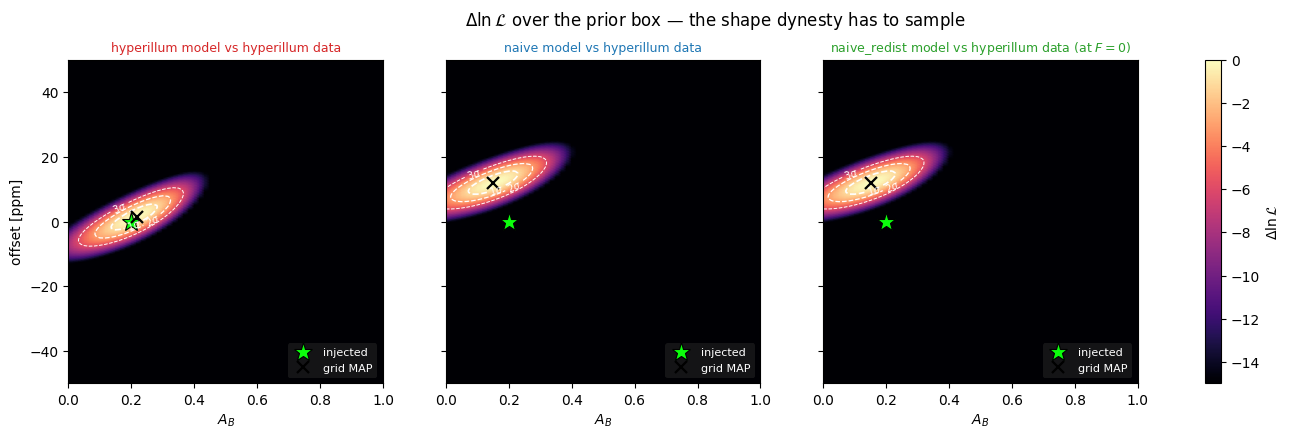

naive_redist 1271 forward models in 19.5 s   grid MAP: A_B = 0.0500, F = 0.0059, lnL = -91.027   (offset profiled out)


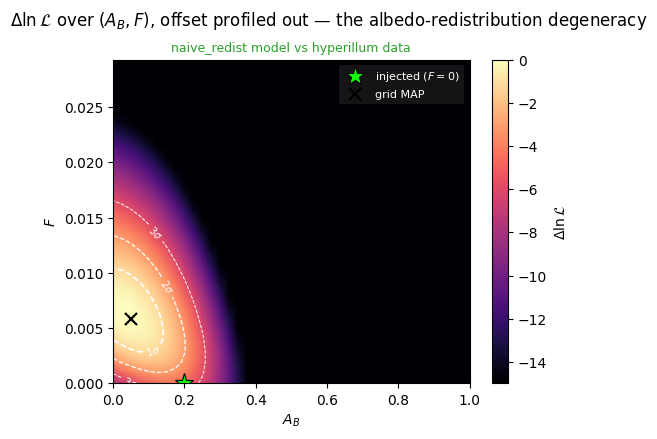

In [5]:
# (A_B, offset) maps: every model side by side, on a shared colour scale
lnL_maps = {}
for name, L in logls.items():
    t0 = time.perf_counter()
    lnL = logl_grid(L, "A_B", A_grid, "offset", O_grid, base, n_jobs=N_JOBS)   # (n_off, n_A_B)
    lnLmax, (off_map, A_map) = grid_max(lnL, O_grid, A_grid)                   # axis order of lnL: (offset, A_B)
    lnL_maps[name] = (lnL, lnLmax, A_map, off_map)
    print(f"{name:12s} {len(A_grid)} forward models in {time.perf_counter()-t0:.1f} s   (caches: {L.cache_used})   grid MAP: A_B = {A_map:.4f}, offset = {off_map:+.2f} ppm, lnL = {lnLmax:.2f}")

fig, axes = plt.subplots(1, len(lnL_maps), figsize=(5.75 * len(lnL_maps), 4.2), sharex=True, sharey=True, squeeze=False)
axes = axes.ravel()
for ax, (name, (lnL, lnLmax, A_map, off_map)) in zip(axes, lnL_maps.items()):
    d = lnL - lnLmax
    im = ax.pcolormesh(A_grid, O_grid, d, vmin=-15, vmax=0., cmap="magma", shading="gouraud")
    cs = ax.contour(A_grid, O_grid, d, levels=[-5.91, -3.09, -1.15], colors="w", linewidths=[0.7, 0.9, 1.2])
    ax.clabel(cs, fmt={-5.91: r"3$\sigma$", -3.09: r"2$\sigma$", -1.15: r"1$\sigma$"}, fontsize=7)
    ax.plot(A_B_true, 0., "*", ms=14, mfc="#0cff0c", mec="k", mew=.8, label="injected")   # not C0/C3: those are the colours of naive/hyperillum
    ax.plot(A_map, off_map, "x", ms=9, color="k", mew=1.6, label="grid MAP")   # the MAP always sits in the bright peak
    ax.set_xlabel("$A_B$")
    ax.set_title(f"{name} model vs {INSOL_TRUTH} data" + (" (at $F = 0$)" if name in F_MODELS else ""), fontsize=9, color=COLOR[name])
    ax.legend(loc="lower right", fontsize=8, labelcolor="w", facecolor="0.15", edgecolor="none", framealpha=.55)
axes[0].set_ylabel("offset [ppm]")
fig.colorbar(im, ax=axes, label=r"$\Delta\ln\mathcal{L}$")   # shared: all panels use vmin=-15, vmax=0
fig.suptitle(r"$\Delta\ln\mathcal{L}$ over the prior box — the shape dynesty has to sample", y=1.0)
plt.show()

# (A_B, F) map of the redistributing model, offset profiled out
lnL_maps_F = {}
if F_MODELS:
    # F range: from the prior floor F = 0 up to where the likelihood along F (the others at the truth) has fallen by 12; F nodes dense towards 0, where it sits
    lo_F, hi_F = PSETS[F_MODELS[0]].bounds[PSETS[F_MODELS[0]].names.index("F")]
    g = lo_F + (hi_F - lo_F) * np.linspace(0., 1., 61) ** 2
    on = np.concatenate([g[(s - s.max()) > -12.] for s in (logl_slice(logls[m], "F", g, base, n_jobs=N_JOBS) for m in F_MODELS)])
    F_LIM = (g[0], min(g[-1], on.max() + 0.5 * np.ptp(on) + 1e-3))
    A_gridF, F_gridF = pset.grid("A_B", 41), np.linspace(*F_LIM, 31)
    for name in F_MODELS:
        t0 = time.perf_counter()
        lnL = logl_grid(logls[name], "A_B", A_gridF, "F", F_gridF, base, n_jobs=N_JOBS, profile_offset=O_grid)   # (n_F, n_A_B)
        lnLmax, (F_map, A_map) = grid_max(lnL, F_gridF, A_gridF)                                                 # axis order of lnL: (F, A_B)
        lnL_maps_F[name] = (lnL, lnLmax, A_map, F_map)
        print(f"{name:12s} {lnL.size} forward models in {time.perf_counter()-t0:.1f} s   grid MAP: A_B = {A_map:.4f}, F = {F_map:.4f}, lnL = {lnLmax:.3f}   (offset profiled out)")

    fig, axes = plt.subplots(1, len(lnL_maps_F), figsize=(5.75 * len(lnL_maps_F), 4.2), squeeze=False)
    for ax, (name, (lnL, lnLmax, A_map, F_map)) in zip(axes.ravel(), lnL_maps_F.items()):
        d = lnL - lnLmax
        im = ax.pcolormesh(A_gridF, F_gridF, d, vmin=-15, vmax=0., cmap="magma", shading="gouraud")
        cs = ax.contour(A_gridF, F_gridF, d, levels=[-5.91, -3.09, -1.15], colors="w", linewidths=[0.7, 0.9, 1.2])
        ax.clabel(cs, fmt={-5.91: r"3$\sigma$", -3.09: r"2$\sigma$", -1.15: r"1$\sigma$"}, fontsize=7)
        ax.plot(A_B_true, base["F"], "*", ms=14, mfc="#0cff0c", mec="k", mew=.8, label="injected ($F=0$)")
        ax.plot(A_map, F_map, "x", ms=9, color="k", mew=1.6, label="grid MAP")
        ax.set_xlabel("$A_B$"); ax.set_ylabel("$F$")
        ax.set_title(f"{name} model vs {INSOL_TRUTH} data", fontsize=9, color=COLOR[name])
        ax.legend(loc="upper right", fontsize=8, labelcolor="w", facecolor="0.15", edgecolor="none", framealpha=.55)
    fig.colorbar(im, ax=axes, label=r"$\Delta\ln\mathcal{L}$")
    fig.suptitle(r"$\Delta\ln\mathcal{L}$ over $(A_B, F)$, offset profiled out — the albedo-redistribution degeneracy", y=1.0)
    plt.show()

## 3. Nested sampling

One dynamic dynesty run per model with all effort on the evidence (`pfrac = 0`); the results go to `dynesty_results/test/`.

In [6]:
# pfrac=0 -> all sampling effort on lnZ (for the Bayes factor; run_dynesty.py uses pfrac=0.8: 80 % of the batch weight on the posterior). The pickles go to dynesty_results/test/, apart from run_dynesty.py's.
sampler = dict(dynamic=True, pfrac=0.0, nlive=500, nlive_batch=250, maxbatch=10, dlogz=0.01, nprocs=12)
tag = dataset_tag(cfg.planet, instrument, cfg.sigma_1min, A_label=A_model.label, A_B=A_B_true, n_bins=n_bins, n_orbits=n_orbits, seed=seed, pfrac=sampler["pfrac"])   # the dataset tag, as run_dynesty.py writes it
scfg = {m: SamplerConfig(seed=seed, outfile=f"dynesty_results/test/{tag}_{{insolation_model}}_priors-{'+'.join(PSETS[m].names)}.pkl", **sampler) for m in MODELS}

fits = {m: run_nested_fit(L, PSETS[m], scfg[m]) for m, L in logls.items()}   # dynesty Results in fits[m].results


5511it [07:16, 12.61it/s, batch: 0 | bound: 10 | nc: 1 | ncall: 23292 | eff(%): 23.660 | loglstar: -89.029 | logz: -94.430 +/-  0.094 | dlogz:  0.000 >  0.010]                            


hyperillum: lnZ = -94.4297 +/- 0.0965,  23292 calls, 7.7 min (20 ms/call)
   CONVERGED | stop 0.965, 0/10 batches, ESS 2040
   saved -> dynesty_results/test/TOI-2431b_MIRI-LRS_fixedA0.1_AB0.2_nbins27_norbits5_rms1min62.9_sigmascale1_seed44_pfrac0_hyperillum_priors-A_B+offset.pkl



5416it [07:11, 12.55it/s, batch: 0 | bound: 10 | nc: 1 | ncall: 22209 | eff(%): 24.387 | loglstar: -95.422 | logz: -100.632 +/-  0.092 | dlogz:  0.000 >  0.010]                           


naive: lnZ = -100.6324 +/- 0.0946,  22209 calls, 7.5 min (20 ms/call)
   CONVERGED | stop 0.946, 0/10 batches, ESS 2004
   saved -> dynesty_results/test/TOI-2431b_MIRI-LRS_fixedA0.1_AB0.2_nbins27_norbits5_rms1min62.9_sigmascale1_seed44_pfrac0_naive_priors-A_B+offset.pkl



 95%|█████████▌| 23355/24507 [37:03<01:49, 10.51it/s, batch: 6 | bound: 16 | nc: 1 | ncall: 107241 | eff(%): 21.778 | loglstar: -91.009 < -92.621 | logz: -100.992 +/-  0.101 | stop:  0.971]   


naive_redist: lnZ = -100.9508 +/- 0.0971,  107241 calls, 21.9 min (12 ms/call)
   CONVERGED | stop 0.971, 6/10 batches, ESS 5598
   saved -> dynesty_results/test/TOI-2431b_MIRI-LRS_fixedA0.1_AB0.2_nbins27_norbits5_rms1min62.9_sigmascale1_seed44_pfrac0_naive_redist_priors-A_B+offset+F.pkl


### 3.1 Evidence and Bayes factor

With two parameters the evidence $Z = \int \mathcal{L}\,\pi\,{\rm d}\theta$ is a 2-D integral that can be computed directly (3-D for `naive_redist`, with nodes dense towards $F = 0$). `edge` is the highest likelihood on the prior boundary relative to the peak: of order unity for `naive_redist` (the physical cut at $F = 0$); for the other two models a value near 1 would mean the prior, not the data, bounds $A_B$.

In [7]:
print(f"{'model':12s} {'NS lnZ':>18s} {'brute force':>12s} {'dlnZ':>9s} {'ncall':>8s} {'edge':>9s}")
for name, fit in fits.items():
    if "F" in PSETS[name].names:   # 3-D: one (offset x A_B) grid per F node; the F nodes are quadratically dense towards 0, where the likelihood is
        F_fine = F_BOUNDS[0] + (F_BOUNDS[1] - F_BOUNDS[0]) * np.linspace(0., 1., 201) ** 2
        lnLf = np.stack([logl_grid(logls[name], "A_B", A_fine, "offset", O_fine, {**base, "F": F_}, n_jobs=N_JOBS) for F_ in F_fine])   # (n_F, n_off, n_A_B)
        lnZ_bf, edge = evidence_bruteforce(lnLf, [F_fine, O_fine, A_fine], bounds=[F_BOUNDS, OFFSET_BOUNDS, A_B_BOUNDS])
    else:
        lnLf = logl_grid(logls[name], "A_B", A_fine, "offset", O_fine, base, n_jobs=N_JOBS)   # 201 forward models per model; the offset axis is analytic
        lnZ_bf, edge = evidence_bruteforce(lnLf, [O_fine, A_fine], bounds=pset.bounds[::-1])   # reversed: logl_grid returns (y, x) = (offset, A_B)
    d = fit.meta["lnZ"] - lnZ_bf
    print(f"{name:12s} {fit.meta['lnZ']:10.4f} +/- {fit.meta['lnZ_err']:.4f} {lnZ_bf:12.4f} {d:+9.4f} "
          f"{fit.meta['ncall']:8d} {edge:9.1e}")
    fit.meta["lnZ_bruteforce"] = lnZ_bf

for den in [m for m in fits if m != INSOL_TRUTH]:
    lnB = fits[INSOL_TRUTH].meta["lnZ"] - fits[den].meta["lnZ"]
    err = np.hypot(fits[INSOL_TRUTH].meta["lnZ_err"], fits[den].meta["lnZ_err"])
    print(f"\nln B ({INSOL_TRUTH} vs {den}) = {lnB:+.3f} +/- {err:.3f}   ->  B = {np.exp(lnB):.3g}")
print("Trotta (2008): |lnB| < 1 inconclusive, 1-2.5 weak, 2.5-5 moderate, > 5 strong")
print("dlnZ should be within a few times logzerr (<~ 0.2); an `edge` near 1 means the PRIOR, not the data, is bounding the parameters (expected of order 1 for naive_redist: the peak sits next to F = 0).")


model                    NS lnZ  brute force      dlnZ    ncall      edge
hyperillum     -94.4297 +/- 0.0965     -94.3751   -0.0546    23292   3.3e-04
naive         -100.6324 +/- 0.0946    -100.6893   +0.0569    22209   2.3e-02
naive_redist  -100.9508 +/- 0.0971    -100.8544   -0.0964   107241   8.6e-01

ln B (hyperillum vs naive) = +6.203 +/- 0.135   ->  B = 494

ln B (hyperillum vs naive_redist) = +6.521 +/- 0.137   ->  B = 679
Trotta (2008): |lnB| < 1 inconclusive, 1-2.5 weak, 2.5-5 moderate, > 5 strong
dlnZ should be within a few times logzerr (<~ 0.2); an `edge` near 1 means the PRIOR, not the data, is bounding the parameters (expected of order 1 for naive_redist: the peak sits next to F = 0).


## 4. Posterior comparison

Post-processing of the `Results` of section 3: 4.1–4.2 cost no likelihood calls, 4.3 `N_DRAWS` forward models per model, 4.4 the noiseless fits.

### 4.1 Corner plot

The posterior density from `res.samples_equal()` (`res.samples` are not posterior-distributed); contours enclose 68 % and 95 % of the mass. Dotted: the profile-likelihood contours of 2.1, which with a uniform prior should coincide up to the sampler's resolution. For `naive_redist` the $(A_B, \mathrm{offset})$ panel is the marginal posterior against the likelihood slice at $F = 0$, so it is wider.

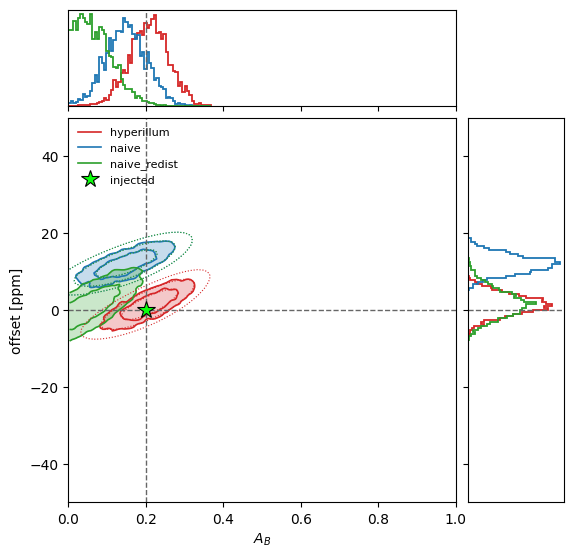

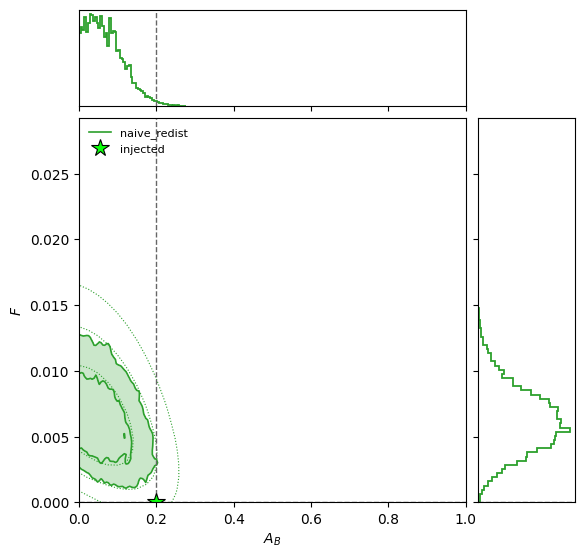

In [8]:
profile = {name: (A_grid, O_grid, lnL) for name, (lnL, *_) in lnL_maps.items()}   # logl_grid returns (offset, A_B), which is what contour(A_grid, O_grid, ...) wants
plot_posterior_overlay(fits, "A_B", "offset", truth=base, profile=profile, colors=COLOR)
plt.show()

if F_MODELS:   # the (A_B, F) plane: filled = the sampler's credible regions, dotted = the profile-likelihood contours of 2.1
    plot_posterior_overlay({m: fits[m] for m in F_MODELS}, "A_B", "F", truth=base, profile={m: (A_gridF, F_gridF, lnL) for m, (lnL, *_) in lnL_maps_F.items()}, colors=COLOR)
    plt.show()

### 4.2 Bias, degeneracy and the Bayes factor

`bayes_factor` quotes two errors: dynesty's `logzerr` in quadrature, and the spread of `jitter_run` realisations, which resample the prior-volume shrinkage without a Gaussian assumption.

hyperillum   ESS 2040, information 4.38 nats
   A_B      =    0.2094 +0.0472 -0.0506   truth 0.2, bias +0.0094 = +0.19 sigma
   offset   =    1.3767 +2.7047 -2.5817   truth 0, bias +1.3767 = +0.52 sigma
   corr(A_B, offset) = +0.811
naive   ESS 2004, information 4.21 nats
   A_B      =    0.1497 +0.0537 -0.0518   truth 0.2, bias -0.0503 = -0.95 sigma
   offset   =   11.9738 +2.3474 -2.4474   truth 0, bias +11.9738 = +4.99 sigma
   corr(A_B, offset) = +0.747
naive_redist   ESS 5598, information 8.59 nats
   A_B      =    0.0626 +0.0545 -0.0412   truth 0.2, bias -0.1374 = -2.87 sigma
   offset   =    1.5920 +3.8192 -3.5335   truth 0, bias +1.5920 = +0.43 sigma
   F        =    0.0061 +0.0025 -0.0022   truth 0, bias +0.0061 = +2.61 sigma
   corr(A_B, offset) = +0.686
   corr(A_B, F) = -0.324
   corr(offset, F) = -0.776
naive_redist: F < 0.0073 (68 %), F < 0.0105 (95 %)   [injected F = 0]
ln B (hyperillum vs naive) = +6.203 +/- 0.135 (analytic) +/- 0.132 (jitter, K=200)  ->  B = 494
P(ln B

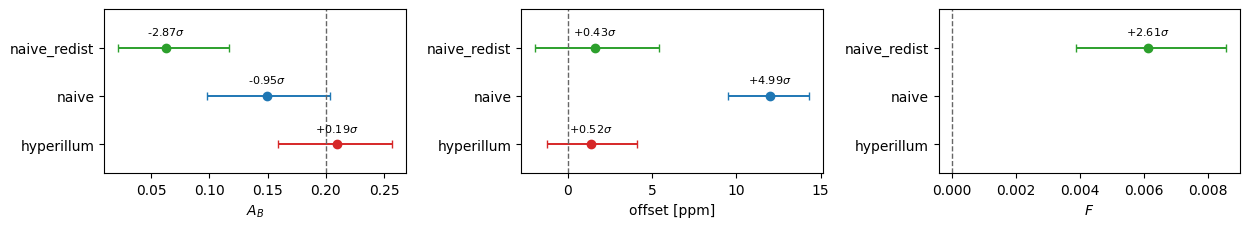

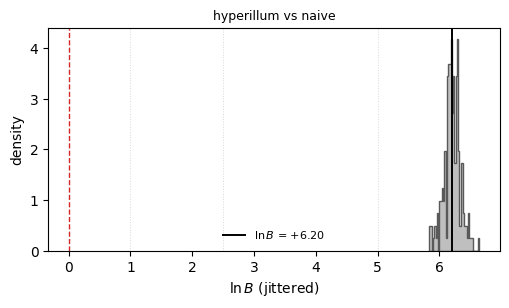

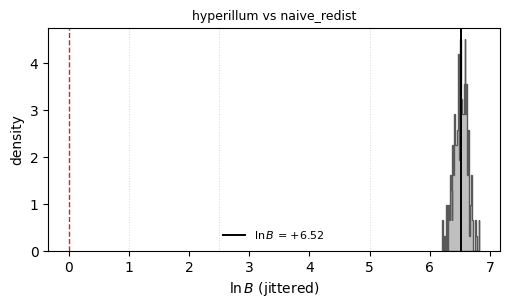

In [9]:
for f in fits.values(): posterior_summary(f, base)
for m in F_MODELS:   # F is one-sided against its F >= 0 prior: upper limits say more than a median +/- interval
    w, iF = fits[m].results.importance_weights(), PSETS[m].names.index("F")
    q68, q95 = dyfunc.quantile(fits[m].results.samples[:, iF], [0.68, 0.95], weights=w)
    print(f"{m}: F < {q68:.4f} (68 %), F < {q95:.4f} (95 %)   [injected F = {base['F']:g}]")

# lnB: "does this dataset contain enough information to distinguish the truth's model from each alternative?"
bfs = {m: bayes_factor(fits, INSOL_TRUTH, m, K=200) for m in fits if m != INSOL_TRUTH}

plot_bias(fits, base, colors=COLOR); plt.show()
for m, bf in bfs.items():
    fig, ax = plot_evidence_jitter(bf); ax.set_title(f"{INSOL_TRUTH} vs {m}", fontsize=9); plt.show()


### 4.3 Derived quantities

The posterior pushed through each model's own temperature map, i.e. what one would infer believing that model. `T_anti` is exactly 0 K for `naive` and `hyperillum` (`T_term` > 0 for `naive` is an interpolation artefact at 90°); `naive_redist` gives its redistributed nightside. The first check compares the occultation depth of `pcurve_params` with the peak of the phase curve, which at these $a/R_\star$ lies below the depth.

hyperillum   occultation_depth  232.30 ppm   phase-curve maximum  220.70 ppm
naive        occultation_depth  228.19 ppm   phase-curve maximum  212.89 ppm
naive_redist occultation_depth  228.19 ppm   phase-curve maximum  212.90 ppm
hyperillum   depth  237.8 +5.4 -5.1 ppm (thermal 231.5, reflected 6.3)   T_bright 2369.8 +36.8 -34.7 K
             T_sub 2701.8 K   T_term 1509.2 K   T_anti    0.0 K
naive        depth  239.5 +4.7 -5.9 ppm (thermal 233.3, reflected 6.2)   T_bright 2382.6 +32.0 -40.5 K
             T_sub 2735.1 K   T_term  552.3 K   T_anti    0.0 K
naive_redist depth  247.0 +4.4 -5.1 ppm (thermal 240.9, reflected 6.2)   T_bright 2433.9 +30.0 -34.6 K
             T_sub 2789.9 K   T_term  799.2 K   T_anti  659.8 K +60.2 -75.7 (< 761 K at 95 %)


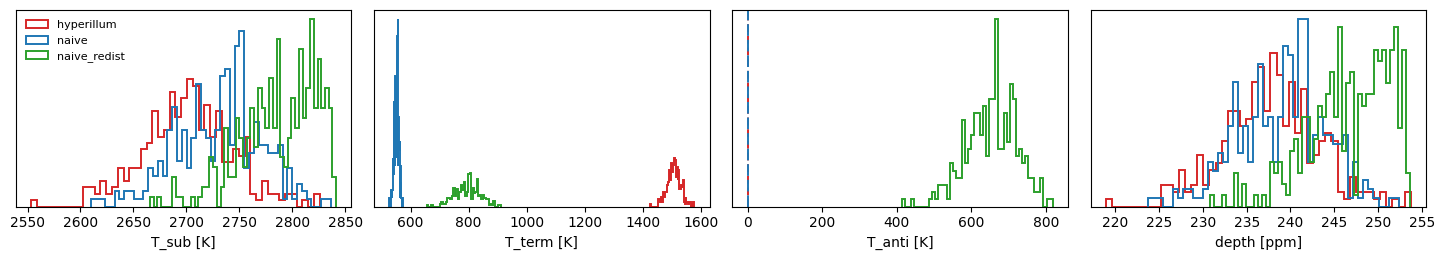

In [10]:
N_DRAWS = 300   # forward models per insolation model (posterior draws)

# Check of pcurve_params: for a thermal-only, transit-free config the occultation depth is close to the peak of the phase curve model_pcurve builds from the same sp.ModelParams.
cfg_th = replace(cfg, reflected=False, transit=False)
for m in fits:
    F_ = base["F"] if "F" in PSETS[m].names else None   # only "naive_redist" has one, and at the injected truth it is 0
    _, y_ = model_pcurve(cfg_th, m, A_B_true, F=F_, n_t=200 * cfg.n_bins)
    d_ = occultation_depth(pcurve_params(cfg_th, m, A_B_true, F=F_), stellar_grid=cfg.stellar_grid, emissivity=cfg_th.emissivity)
    print(f"{m:12s} occultation_depth {d_:7.2f} ppm   phase-curve maximum {y_.max():7.2f} ppm")

der = {m: derived_samples(logls[m], equal_samples(fits[m], N_DRAWS, seed=0), n_jobs=N_JOBS) for m in fits}
for name, d in der.items():
    q, q_th = np.percentile(d["depth"], [16, 50, 84]), np.percentile(d["depth_th"], [16, 50, 84])
    Tb = brightness_temperature(d["depth_th"], cfg)
    print(f"{name:12s} depth {q[1]:6.1f} +{q[2]-q[1]:.1f} -{q[1]-q[0]:.1f} ppm (thermal {q_th[1]:.1f}, reflected {np.median(d['depth_refl']):.1f})   T_bright {Tb[1]:6.1f} +{Tb[2]-Tb[1]:.1f} -{Tb[1]-Tb[0]:.1f} K")
    Ta = np.percentile(d["T_anti"], [16, 50, 84, 95])
    print(f"{'':12s} T_sub {np.median(d['T_sub']):6.1f} K   T_term {np.median(d['T_term']):6.1f} K   T_anti {Ta[1]:6.1f} K" + (f" +{Ta[2]-Ta[1]:.1f} -{Ta[1]-Ta[0]:.1f} (< {Ta[3]:.0f} K at 95 %)" if name in F_MODELS else ""))

KEYS = ("T_sub", "T_term", "T_anti", "depth") if F_MODELS else ("T_sub", "T_term", "depth")
plot_derived(der, keys=KEYS, colors=COLOR); plt.show()

### 4.4 Noisy fit vs the noiseless truth

The posterior medians of this dataset against the least-squares fits of the misspecified models to the noiseless truth (`fit_naive`; `fit_redist` with the false-positive $F$ and its nightside temperature), i.e. the bias, in units of the posterior width and of the Fisher $\sigma$. Lower panel: everything minus the binned truth against $\pm\sigma_{\rm bin}$, with the data (black) and the numerical floor (dotted), which should sit on zero.

hyperillum   median   A_B 0.2094 (+0.0094 = +0.19 sigma)   offset   +1.38 ppm (+1.38 = +0.52 sigma)   chi2 vs truth   0.40   vs data  15.22
             max-lnL  A_B 0.2112 (+0.0112)              offset   +1.45 ppm (+1.45)           chi2 vs truth   0.41   vs data  15.22
naive        median   A_B 0.1497 (-0.0503 = -0.95 sigma)   offset  +11.97 ppm (+11.97 = +4.99 sigma)   chi2 vs truth  13.10   vs data  28.01
             max-lnL  A_B 0.1531 (-0.0469)              offset  +12.07 ppm (+12.07)           chi2 vs truth  13.11   vs data  28.01
naive_redist median   A_B 0.0626 (-0.1374 = -2.87 sigma)   offset   +1.59 ppm (+1.59 = +0.43 sigma)   F 0.0061 (+0.0061)   chi2 vs truth   5.47   vs data  19.32
             max-lnL  A_B 0.0399 (-0.1601)              offset   +0.49 ppm (+0.49)   F 0.0061 (+0.0061)           chi2 vs truth   4.99   vs data  19.17

NOISELESS fit(s) to the NOISELESS truth  (offset free, no noise, no seed - this is THE bias; the least-squares fits of the bias analysis):
   

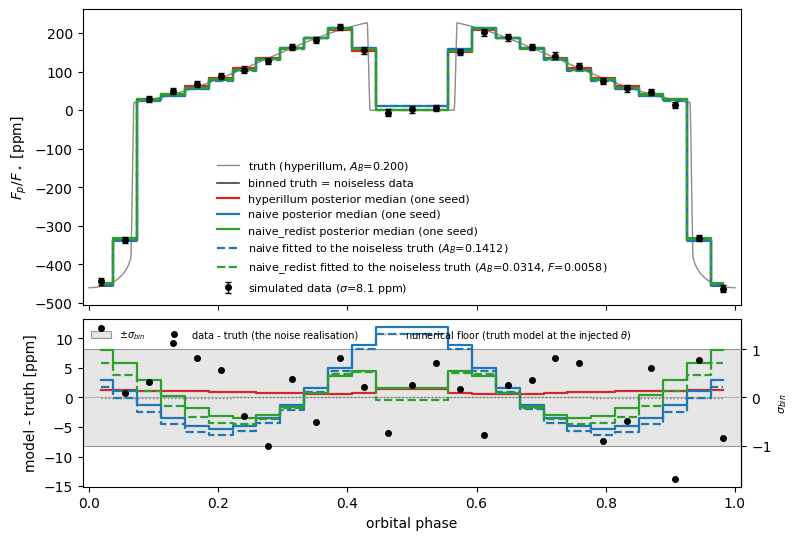

In [11]:
fig, (ax, axr), out = plot_noisy_vs_truth(cfg, data, logls, fits, A_B_true, base, insolation_truth=INSOL_TRUTH, colors=COLOR, verbose=True)   # the noiseless fits (the bias) in A_B_FIT_BOUNDS, as in the bias analysis
plt.show()
